# Akamai CCM *lineage* demo

[Akamai Cloud Certificate Manager](https://techdocs.akamai.com/ccm/docs/welcome) (CCM) is the next-generation CPS, which will simplify the management of third-party certificates.

This API-based demo creates a **certificate lineage**, requests a CSR from the [V2 CCM API](https://techdocs.akamai.com/ccm/reference/post-lineages), signs it with a local demo CA, uploads the signed certificate, and requests activation on staging and production. A lineage keeps future certificate generations tied to the same hostname binding, so you don't need to update the property after a CCM certificate is renewed.

> **Note:** The certificate is self-signed for demonstration purposes. Use a trusted CA-issued certificate in production.

> **Note:** Working directly with the API is just one way to manage CCM certificates. If you prefer a higher-level approach, both the [Akamai Terraform provider](https://techdocs.akamai.com/terraform/docs/ccm-integration-guide) and the Akamai Control Center UI are also viable options.

## How a Lineage Is Structured

A [certificate lineage](https://techdocs.akamai.com/ccm/docs/key-concepts-and-terms#certificate-lineages) is a continuous sequence of renewed certificates managed under one permanent identity, instead of a set of independent, standalone certificate objects. It has three tiers:

| Tier | What it holds |
| --- | --- |
| **Lineage** | The fixed configuration — `lineageId`, subject, SANs, `keySpecs`, secure network. This identity never changes. |
| **Generation** | One rotation period. Every renewal creates a new *head* generation. |
| **Algorithm instance** | The signed certificate for a single key type (`ECDSA`, `RSA`, or both). |

CCM keeps a rolling three-instance window of generations: a **pending** one you prepare and stage, an **active** one serving production traffic, and the **previous** one kept as an instant rollback target.

Once your hostnames are bound to the lineage ID, all later rotations, staging tests, production activations, and rollbacks happen inside CCM — no Property Manager edit or activation required.

The cell below draws this model (the IDs shown are illustrative):

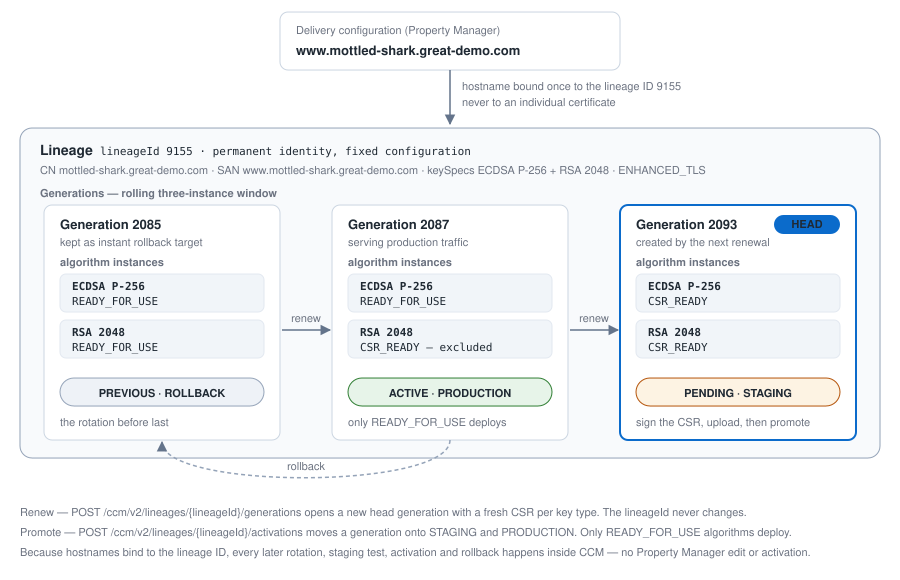

In [28]:
# Conceptual diagram of a CCM certificate lineage. Static illustration, no API calls.
from IPython.display import SVG, display

lineage_svg = """
<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 900 580" width="900" role="img"
     aria-label="CCM certificate lineage: hostnames bind to a permanent lineage ID, which holds a rolling window of pending, active and previous generations, each containing one algorithm instance per key type.">
  <defs>
    <marker id="arrow" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse">
      <path d="M 0 0 L 10 5 L 0 10 z" fill="#64748b"/>
    </marker>
  </defs>
  <style>
    .t   { font-family: -apple-system, "Segoe UI", Helvetica, Arial, sans-serif; fill: #1f2933; }
    .ttl { font-size: 14px; font-weight: 600; }
    .lbl { font-size: 13px; font-weight: 600; }
    .sm  { font-size: 11px; fill: #6b7280; }
    .mono{ font-family: ui-monospace, SFMono-Regular, Menlo, monospace; font-size: 11px; }
    .pill{ font-size: 11px; font-weight: 600; }
    .box { fill: #ffffff; stroke: #cbd5e1; }
    .chip{ fill: #f1f5f9; stroke: #e2e8f0; }
  </style>

  <!-- tier 0: the property -->
  <rect class="box" x="280" y="12" width="340" height="58" rx="8"/>
  <text class="t sm" x="296" y="34">Delivery configuration (Property Manager)</text>
  <text class="t lbl" x="296" y="55">www.mottled-shark.great-demo.com</text>

  <line x1="450" y1="70" x2="450" y2="124" stroke="#64748b" stroke-width="1.5" marker-end="url(#arrow)"/>
  <text class="t sm" x="462" y="90">hostname bound once to the lineage ID 9155</text>
  <text class="t sm" x="462" y="106">never to an individual certificate</text>

  <!-- tier 1: the lineage -->
  <rect x="20" y="128" width="860" height="330" rx="12" fill="#f8fafc" stroke="#94a3b8"/>
  <text class="t ttl" x="40" y="155">Lineage</text>
  <text class="t mono" x="100" y="155" fill="#6b7280">lineageId 9155 · permanent identity, fixed configuration</text>
  <text class="t sm" x="40" y="174">CN mottled-shark.great-demo.com · SAN www.mottled-shark.great-demo.com · keySpecs ECDSA P-256 + RSA 2048 · ENHANCED_TLS</text>

  <!-- tier 2: generations, three-instance rolling window -->
  <text class="t sm" x="40" y="197" font-weight="600" fill="#475569">Generations — rolling three-instance window</text>

  <!-- previous -->
  <rect class="box" x="44" y="205" width="236" height="235" rx="8"/>
  <text class="t lbl" x="60" y="229">Generation 2085</text>
  <text class="t sm" x="60" y="246">kept as instant rollback target</text>
  <text class="t sm" x="60" y="266" font-weight="600" fill="#475569">algorithm instances</text>
  <rect class="chip" x="60" y="274" width="204" height="38" rx="6"/>
  <text class="t mono" x="72" y="290" font-weight="600">ECDSA P-256</text>
  <text class="t mono" x="72" y="305" fill="#6b7280">READY_FOR_USE</text>
  <rect class="chip" x="60" y="320" width="204" height="38" rx="6"/>
  <text class="t mono" x="72" y="336" font-weight="600">RSA 2048</text>
  <text class="t mono" x="72" y="351" fill="#6b7280">READY_FOR_USE</text>
  <rect x="60" y="378" width="204" height="28" rx="14" fill="#eef2f7" stroke="#94a3b8"/>
  <text class="t pill" x="162" y="397" text-anchor="middle" fill="#475569">PREVIOUS · ROLLBACK</text>
  <text class="t sm" x="60" y="426">the rotation before last</text>

  <!-- active -->
  <rect class="box" x="332" y="205" width="236" height="235" rx="8"/>
  <text class="t lbl" x="348" y="229">Generation 2087</text>
  <text class="t sm" x="348" y="246">serving production traffic</text>
  <text class="t sm" x="348" y="266" font-weight="600" fill="#475569">algorithm instances</text>
  <rect class="chip" x="348" y="274" width="204" height="38" rx="6"/>
  <text class="t mono" x="360" y="290" font-weight="600">ECDSA P-256</text>
  <text class="t mono" x="360" y="305" fill="#6b7280">READY_FOR_USE</text>
  <rect class="chip" x="348" y="320" width="204" height="38" rx="6"/>
  <text class="t mono" x="360" y="336" font-weight="600">RSA 2048</text>
  <text class="t mono" x="360" y="351" fill="#b45309">CSR_READY — excluded</text>
  <rect x="348" y="378" width="204" height="28" rx="14" fill="#e7f4e9" stroke="#2e7d32"/>
  <text class="t pill" x="450" y="397" text-anchor="middle" fill="#1e5c23">ACTIVE · PRODUCTION</text>
  <text class="t sm" x="348" y="426">only READY_FOR_USE deploys</text>

  <!-- pending / head -->
  <rect x="620" y="205" width="236" height="235" rx="8" fill="#ffffff" stroke="#0b6bcb" stroke-width="2"/>
  <text class="t lbl" x="636" y="229">Generation 2093</text>
  <rect x="774" y="215" width="66" height="19" rx="9.5" fill="#0b6bcb"/>
  <text class="t pill" x="807" y="228" text-anchor="middle" fill="#ffffff">HEAD</text>
  <text class="t sm" x="636" y="246">created by the next renewal</text>
  <text class="t sm" x="636" y="266" font-weight="600" fill="#475569">algorithm instances</text>
  <rect class="chip" x="636" y="274" width="204" height="38" rx="6"/>
  <text class="t mono" x="648" y="290" font-weight="600">ECDSA P-256</text>
  <text class="t mono" x="648" y="305" fill="#6b7280">CSR_READY</text>
  <rect class="chip" x="636" y="320" width="204" height="38" rx="6"/>
  <text class="t mono" x="648" y="336" font-weight="600">RSA 2048</text>
  <text class="t mono" x="648" y="351" fill="#6b7280">CSR_READY</text>
  <rect x="636" y="378" width="204" height="28" rx="14" fill="#fdf3e3" stroke="#b45309"/>
  <text class="t pill" x="738" y="397" text-anchor="middle" fill="#8a4208">PENDING · STAGING</text>
  <text class="t sm" x="636" y="426">sign the CSR, upload, then promote</text>

  <!-- rotation arrows -->
  <line x1="282" y1="330" x2="330" y2="330" stroke="#64748b" stroke-width="1.5" marker-end="url(#arrow)"/>
  <text class="t sm" x="306" y="322" text-anchor="middle">renew</text>
  <line x1="570" y1="330" x2="618" y2="330" stroke="#64748b" stroke-width="1.5" marker-end="url(#arrow)"/>
  <text class="t sm" x="594" y="322" text-anchor="middle">renew</text>
  <path d="M 450 440 C 450 490 162 490 162 442" fill="none" stroke="#94a3b8" stroke-width="1.5"
        stroke-dasharray="4 3" marker-end="url(#arrow)"/>
  <text class="t sm" x="306" y="470" text-anchor="middle" fill="#64748b">rollback</text>

  <!-- footnotes -->
  <text class="t sm" x="20" y="516">Renew — POST /ccm/v2/lineages/{lineageId}/generations opens a new head generation with a fresh CSR per key type. The lineageId never changes.</text>
  <text class="t sm" x="20" y="536">Promote — POST /ccm/v2/lineages/{lineageId}/activations moves a generation onto STAGING and PRODUCTION. Only READY_FOR_USE algorithms deploy.</text>
  <text class="t sm" x="20" y="556">Because hostnames bind to the lineage ID, every later rotation, staging test, activation and rollback happens inside CCM — no Property Manager edit or activation.</text>
</svg>
"""

display(SVG(lineage_svg))

## Set Up EdgeGrid Session

Let's first set up an EdgeGrid session using information from the `~/.edgerc` file. The correct *section* can be set via `export AKAMAI_EDGEGRID_SECTION=section`; otherwise, `default` is going to be used.

Make sure your API user has the [CCM permissions](https://techdocs.akamai.com/ccm/reference/get-started).

This notebook supports the `AccountSwitchKey` option which can be set via `export AKAMAI_ACCOUNT_SWITCH_KEY="1-2345:A-BCDE"`

*Make sure to select a `section` or `AccountSwitchKey` that has CCM enabled on that contract!*

In [ ]:
import json
import os

import requests
from akamai.edgegrid import EdgeGridAuth, EdgeRc

edgerc_path = os.path.expanduser("~/.edgerc")

if not os.path.exists(edgerc_path):
    raise FileNotFoundError(f"Could not find .edgerc at {edgerc_path}")

section = os.getenv("AKAMAI_EDGEGRID_SECTION", "default")
account_switch_key = os.getenv("AKAMAI_ACCOUNT_SWITCH_KEY")

edgerc = EdgeRc(edgerc_path)
host = edgerc.get(section, "host")

session = requests.Session()
session.auth = EdgeGridAuth.from_edgerc(edgerc, section)
session.headers.update({
    "Accept": "application/json",
    "Content-Type": "application/json",
})

base_url = f"https://{host}"
print(f"EdgeGrid session configured for host: {host}")

if account_switch_key:
    print(f"Using AccountSwitchKey: {account_switch_key}")

## Create Lineage Certificate Signing Request

You need a `contractId` and `groupId` so the certificate lineage is created in the correct contract and group in your Akamai account.

Set them before running the notebook:

`export AKAMAI_CONTRACT_ID="ABC"`  
`export AKAMAI_GROUP_ID="123"`

> Set `GROUP_ID` and `CONTRACT_ID` without the `grp_` or `ctr_` prefix.

The V2 API creates a lineage and returns a CSR for every entry in `keySpecs`. This example requests a `ECDSA` P-256 and `RSA` CSR on the `ENHANCED_TLS` network with a CN and one SAN.

### Request Payload

The payload options are documented in the [CCM API reference](https://techdocs.akamai.com/ccm/reference/api). The lineage endpoint is `POST /ccm/v2/lineages`.

In [ ]:
from coolname import generate_slug

contract_id = os.getenv("AKAMAI_CONTRACT_ID")
group_id_value = os.getenv("AKAMAI_GROUP_ID")

if not contract_id or not group_id_value:
    raise ValueError(
        "Set AKAMAI_CONTRACT_ID and AKAMAI_GROUP_ID before creating a lineage."
    )

try:
    group_id = int(group_id_value)
except ValueError as error:
    raise ValueError("AKAMAI_GROUP_ID must be a numeric group ID.") from error

# Account switch key is optional and already read in the setup cell.
params = {}
if account_switch_key:
    params["accountSwitchKey"] = account_switch_key

random_name = generate_slug(2)
demo_base_domain = os.getenv("AKAMAI_DEMO_BASE_DOMAIN", "great-demo.com")
common_name = f"{random_name}.{demo_base_domain}"
san_name = f"www.{common_name}"
lineage_name = f"CCM API Lineage Demo {random_name}"

payload = {
    "contractId": contract_id,
    "groupId": group_id,
    "lineageName": lineage_name,
    "secureNetwork": "ENHANCED_TLS",
    "keySpecs": [
        {
            "keyType": "ECDSA",
            "keySize": "P-256",
        },
        {
            "keySize": "2048",
            "keyType": "RSA"
        }
    ],
    "subject": {
        "commonName": common_name,
        "country": "NL",
        "locality": "Amsterdam",
        "organization": "Akamai Great Demo",
        "state": "Noord-Holland",
    },
    "sans": [san_name],
}

print("Using demo names:")
print("  lineageName:", lineage_name)
print("  commonName:", common_name)
print("  san:", san_name)

url = f"{base_url}/ccm/v2/lineages"
response = session.post(url, params=params, json=payload, timeout=30)

print("Status:", response.status_code)
try:
    response_json = response.json()
except ValueError:
    response_json = {"raw": response.text}

if not response.ok:
    print("Request failed:")
    print(json.dumps(response_json, indent=2))
    response.raise_for_status()

print("Lineage request created:")
print(json.dumps(response_json, indent=2))

## Get CSR PEM

When successful, you should see your CSR in CCM on Akamai Control Center:  


Now, get the PEM from this CSR; we're going to use that to request the certificate and for this demo, only signing the ECSA certificate.

In [ ]:
# Extract the ECDSA CSR from the lineage response.
if "response_json" not in globals():
    raise RuntimeError("Run the previous request cell first to populate response_json.")

if not isinstance(response_json, dict):
    raise TypeError("response_json is not a JSON object; cannot extract the lineage CSR.")

lineage_id = response_json.get("lineageId")
head = response_json.get("head") or {}
generation_id = head.get("headGenerationId")
algorithms = head.get("algorithms") or []
algorithm = next(
    (item for item in algorithms if item.get("keyType") == "ECDSA"),
    None,
)

if not lineage_id or not generation_id or not algorithm:
    print("Unexpected lineage response:", json.dumps(response_json, indent=2))
    raise KeyError("lineageId, head.headGenerationId, or ECDSA CSR was not found.")

csr_pem = algorithm.get("csrPem")
if not csr_pem:
    print("Lineage algorithms:", json.dumps(algorithms, indent=2))
    raise KeyError("csrPem was not found for the ECDSA algorithm.")

print("Lineage CSR extracted and ready for certificate signing.")
print("lineageId:", lineage_id)
print("generationId:", generation_id)
print("keyType:", algorithm["keyType"])
print(csr_pem)

## Request Certificate

Now that we have the CSR, use it to generate a privately signed certificate.  
For this demo, we sign it ourselves — in production, you would submit the CSR to your preferred CA to obtain a trusted certificate.

In [ ]:
from datetime import UTC, datetime, timedelta

from cryptography import x509
from cryptography.hazmat.primitives import hashes, serialization
from cryptography.hazmat.primitives.asymmetric import ec
from cryptography.x509.oid import NameOID

if "csr_pem" not in globals() or not csr_pem:
    raise RuntimeError("Run the Get csrPEM cell first so csr_pem is available.")

csr = x509.load_pem_x509_csr(csr_pem.encode())
if not csr.is_signature_valid:
    raise ValueError("CSR signature is not valid.")

cn_attrs = csr.subject.get_attributes_for_oid(NameOID.COMMON_NAME)
common_name = cn_attrs[0].value if cn_attrs else "demo.local"

try:
    san_ext = csr.extensions.get_extension_for_class(x509.SubjectAlternativeName)
    san_value = san_ext.value
except x509.ExtensionNotFound:
    san_value = x509.SubjectAlternativeName([x509.DNSName(common_name)])

ca_key = ec.generate_private_key(ec.SECP256R1())
ca_subject = x509.Name([
    x509.NameAttribute(NameOID.COUNTRY_NAME, "NL"),
    x509.NameAttribute(NameOID.ORGANIZATION_NAME, "Demo Local CA"),
    x509.NameAttribute(NameOID.COMMON_NAME, "Demo Self-Signed Root"),
])

now = datetime.now(UTC)
ca_cert = (
    x509.CertificateBuilder()
    .subject_name(ca_subject)
    .issuer_name(ca_subject)
    .public_key(ca_key.public_key())
    .serial_number(x509.random_serial_number())
    .not_valid_before(now - timedelta(minutes=5))
    .not_valid_after(now + timedelta(days=365))
    .add_extension(x509.BasicConstraints(ca=True, path_length=None), critical=True)
    .sign(private_key=ca_key, algorithm=hashes.SHA256())
)

demo_cert = (
    x509.CertificateBuilder()
    .subject_name(csr.subject)
    .issuer_name(ca_cert.subject)
    .public_key(csr.public_key())
    .serial_number(x509.random_serial_number())
    .not_valid_before(now - timedelta(minutes=5))
    .not_valid_after(now + timedelta(days=180))
    .add_extension(x509.BasicConstraints(ca=False, path_length=None), critical=True)
    .add_extension(san_value, critical=False)
    .sign(private_key=ca_key, algorithm=hashes.SHA256())
)

demo_cert_pem = demo_cert.public_bytes(serialization.Encoding.PEM).decode()
demo_ca_pem = ca_cert.public_bytes(serialization.Encoding.PEM).decode()

print("Created local demo certificate from CSR.")
print("Subject CN:", common_name)

## Validate Domain Ownership

Before you can upload the certificate, you should validate [domain ownership](https://techdocs.akamai.com/domain-validation/docs/welcome) for the CN and SAN. If the CN and SAN are found, you are good to go; if not, first validate the HOST or DOMAIN using the [Domain Ownership Manager](https://control.akamai.com/apps/domain-validation).

> **Note:** This is a different procedure as with *normal* CPS/SBD certificates. It's the Cloud Certificate Manager that already checks the validation status of every Subject Alternative Name (SAN) and Common Name (CN) using Domain Ownership Manager (DOM). If you are not the owner of a domain or hostname you can't use it in your certificate.

In [ ]:
# Verify all SANs are validated in the Domain Ownership Manager before uploading.
if "response_json" not in globals() or not isinstance(response_json, dict):
    raise RuntimeError("Run the certificate request cell first to get response_json.")

domains_to_check = [
    {"domainName": domain, "validationScope": "HOST"}
    for domain in response_json.get("sans", [])
]

if not domains_to_check:
    raise RuntimeError("No SANs found in response_json; cannot validate domains.")

dv_params = {}
if account_switch_key:
    dv_params["accountSwitchKey"] = account_switch_key

dv_url = f"{base_url}/domain-validation/v1/domains/search"
dv_response = session.post(dv_url, params=dv_params, json={"domains": domains_to_check}, timeout=30)

print("Domain validation check status:", dv_response.status_code)
dv_response.raise_for_status()
dv_json = dv_response.json()

print(json.dumps(dv_json, indent=2))

requested = {d["domainName"] for d in domains_to_check}
returned = {d["domainName"] for d in dv_json.get("domains", [])}
missing = requested - returned

if missing:
    for domain in sorted(missing):
        print(f"  missing: {domain}")
    raise RuntimeError(
        f"{len(missing)} domain(s) not found in Domain Ownership Manager — validate them before uploading."
    )

print("\nAll domains validated — proceeding to upload.")

## Upload and Activate Lineage Generation

After the signed certificate is created, upload it to the head generation with `PATCH /ccm/v2/lineages/{lineageId}/generations/{generationId}`. Then promote that generation to both staging and production with `POST /ccm/v2/lineages/{lineageId}/activations`.

The upload request uses the CCM lineage vendor media type in its `Accept` header. The certificate and trust chain below are generated locally for this demo; use a trusted CA-issued certificate in production.

In [ ]:
if "session" not in globals() or "base_url" not in globals():
    raise RuntimeError("Run the EdgeGrid setup cell first.")

if "lineage_id" not in globals() or "generation_id" not in globals():
    raise RuntimeError("Run the lineage request and CSR extraction cells first.")

if "demo_cert_pem" not in globals() or "demo_ca_pem" not in globals():
    raise RuntimeError("Run the certificate signing cell first.")

upload_params = {"acknowledgeWarnings": "true"}
if account_switch_key:
    upload_params["accountSwitchKey"] = account_switch_key

upload_payload = {
    "algorithms": {
        "ECDSA": {
            "signedCertificatePem": demo_cert_pem,
            "trustChainPem": demo_ca_pem,
        }
    }
}

upload_url = f"{base_url}/ccm/v2/lineages/{lineage_id}/generations/{generation_id}"
upload_headers = {
    "Accept": "application/prs.akamai.cps-ccm-api.third-party.certificate-lineage-create.v3+json; charset=UTF-8",
}
upload_response = session.patch(
    upload_url,
    params=upload_params,
    headers=upload_headers,
    json=upload_payload,
    timeout=30,
)

print("Upload status:", upload_response.status_code)
try:
    upload_response_json = upload_response.json()
except ValueError:
    upload_response_json = {"raw": upload_response.text}

if not upload_response.ok:
    print("Upload failed:")
    print(json.dumps(upload_response_json, indent=2))
    upload_response.raise_for_status()

print("Signed certificate uploaded:")
print(json.dumps(upload_response_json, indent=2))

activation_params = {}
if account_switch_key:
    activation_params["accountSwitchKey"] = account_switch_key

activation_payload = {
    "operationType": "PROMOTE",
    "generationId": generation_id,
    "networks": ["STAGING", "PRODUCTION"],
}
activation_url = f"{base_url}/ccm/v2/lineages/{lineage_id}/activations"
activation_response = session.post(
    activation_url,
    params=activation_params,
    json=activation_payload,
    timeout=30,
)

print("Activation status:", activation_response.status_code)
if activation_response.status_code == 204:
    activation_response_json = {}
elif activation_response.status_code == 202:
    try:
        activation_response_json = activation_response.json()
    except ValueError:
        activation_response_json = {"raw": activation_response.text}
else:
    try:
        activation_response_json = activation_response.json()
    except ValueError:
        activation_response_json = {"raw": activation_response.text}
    print("Activation failed:")
    print(json.dumps(activation_response_json, indent=2))
    activation_response.raise_for_status()

print("Lineage generation activation requested for staging and production:")
print(json.dumps(activation_response_json, indent=2))

## Ready to Use

Now you should be ready to use the certificate and you should see this in the Cloud Certificate Manager (CCM).

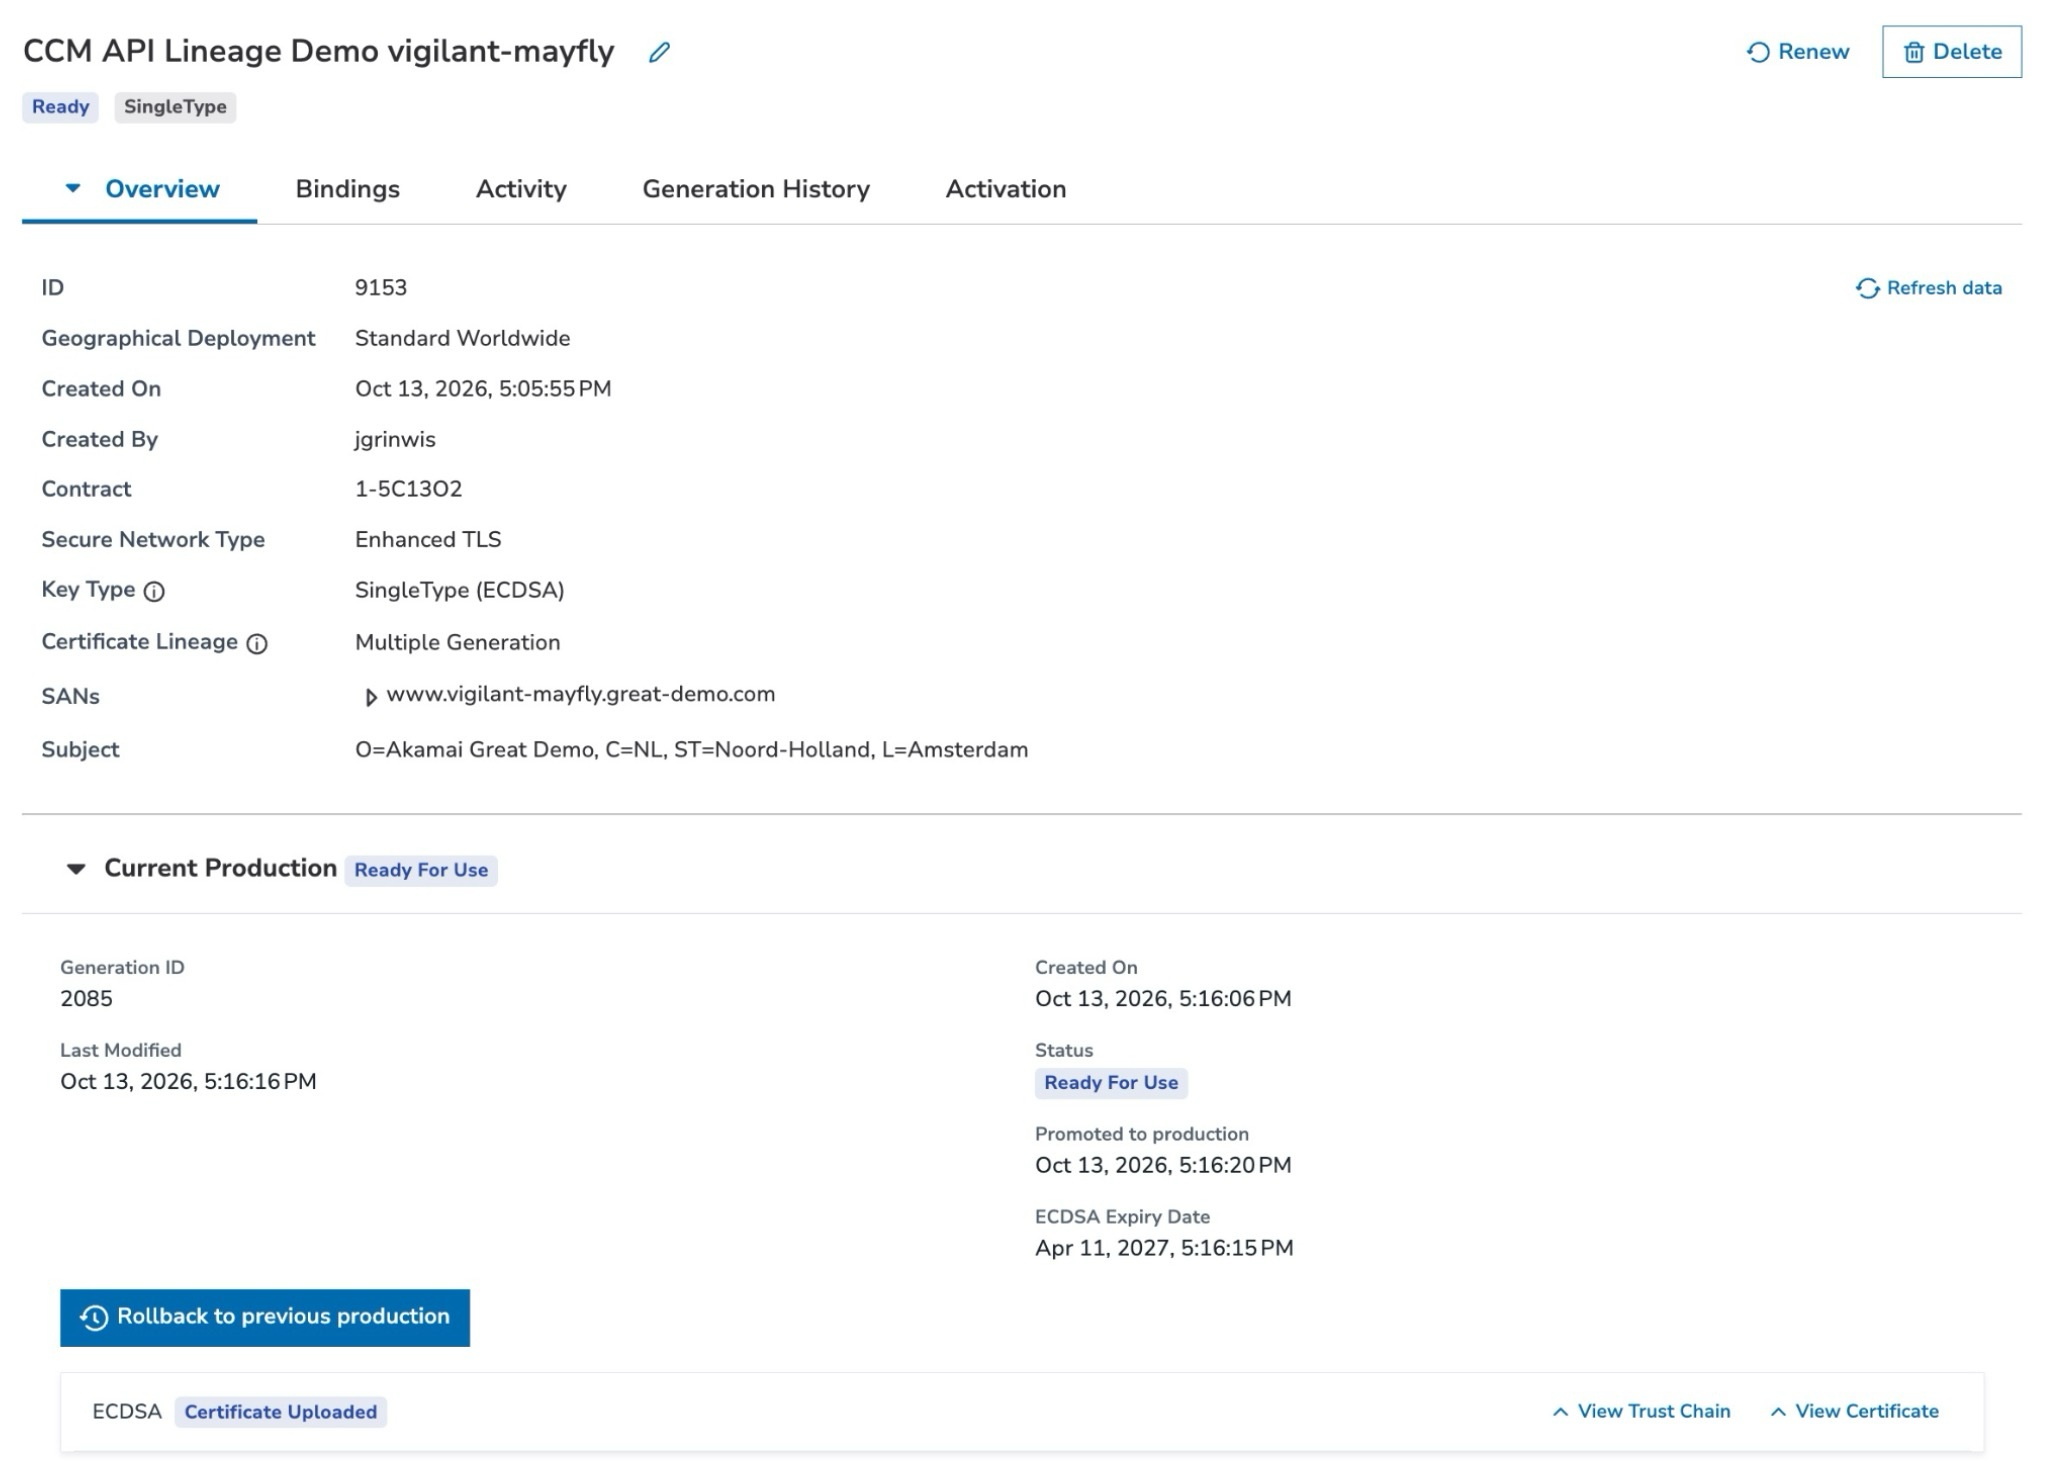

## Assign Certificate to hostname
Your newly created CCM certificate can now be assigned in your delivery configuration to a hostname:

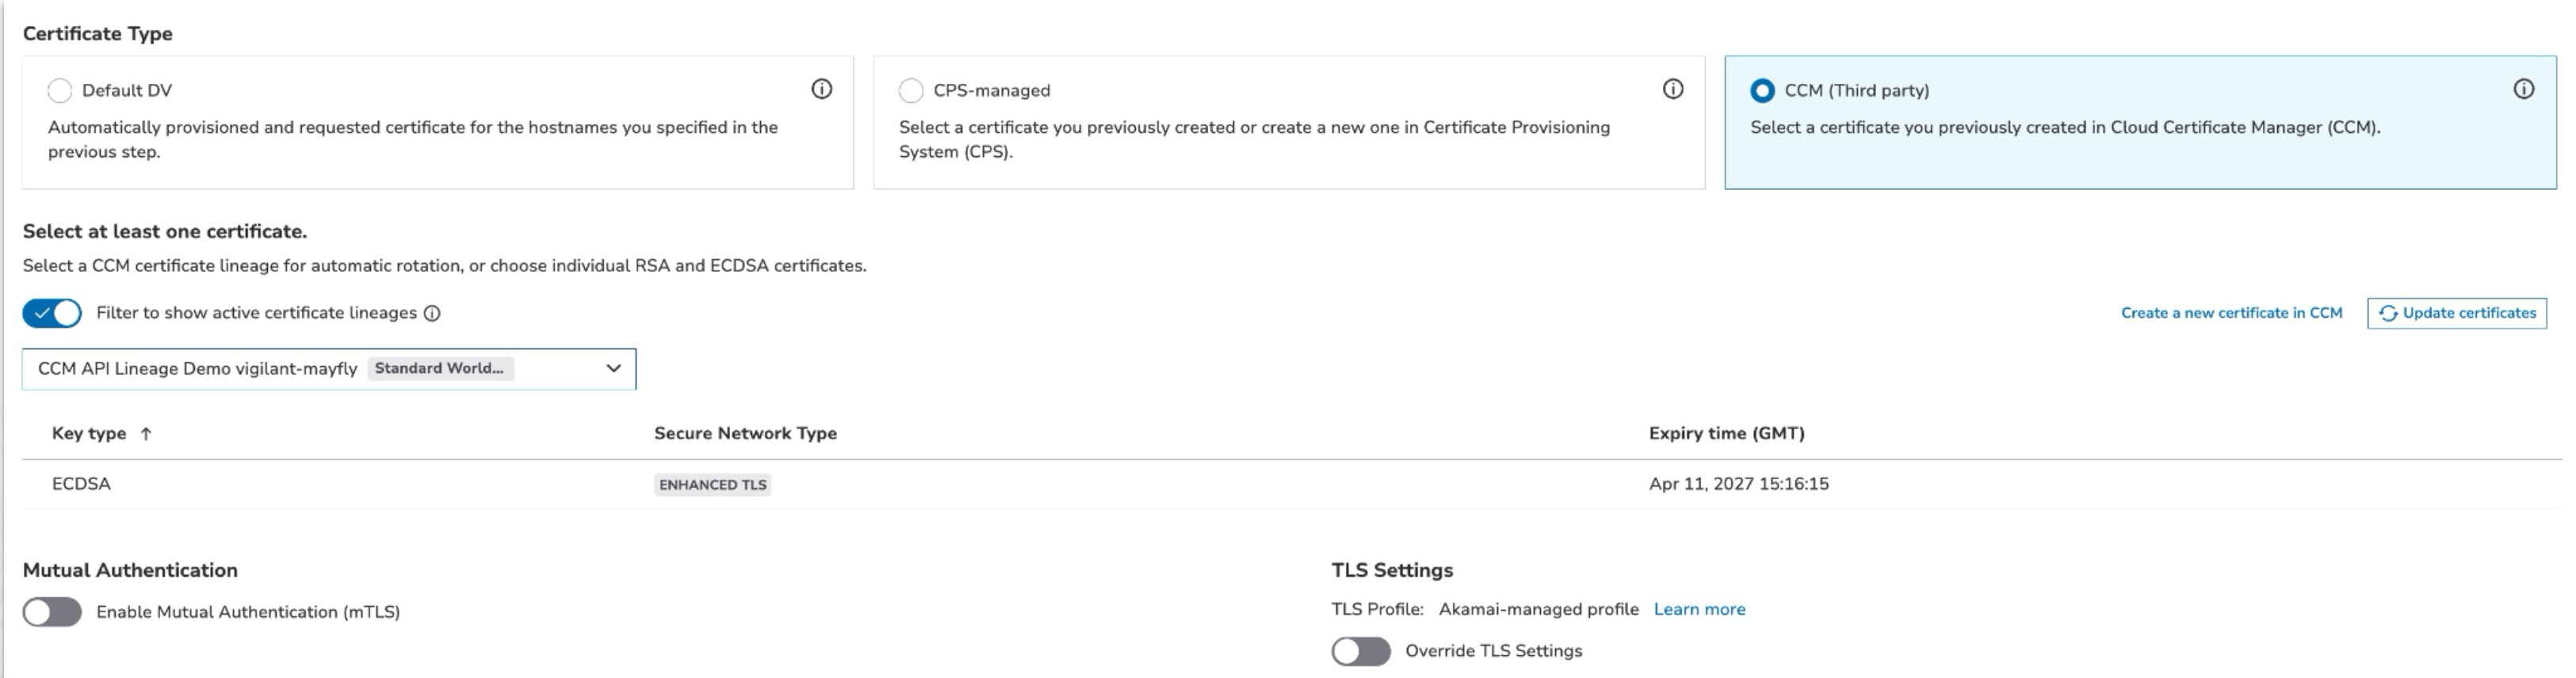

> **Note:** This is different from the CPS workflow. In CPS, the certificate was tied to a hostname during the certificate provisioning process itself. With CCM, certificate management and hostname assignment are separate — you assign the certificate to a hostname directly in your delivery configuration, giving you more flexibility as you have the option to select your certificate. But beware of **VIP** certificates; they are hard-linked to a slot number, so you need to change the edgehostname.

Push to staging to test, and once everything looks good, push to production.

In [ ]:
# Set to False to skip the V2 renewal demo.
demo_renew = True

## Renew the Lineage

A lineage renewal creates a new head generation with fresh CSRs for every key type in the lineage. The existing generation remains connected to the same lineage and hostname binding.

The V2 workflow is:

1. **POST** `/ccm/v2/lineages/{lineageId}/generations?confirmAbandonHead=true` to create the new head generation.
2. Extract the new generation's CSR, sign it with the CA, and upload it with the V2 generation endpoint.
3. Promote the renewed generation to staging and production.

> Renewal can be rejected when the lineage state has a head generation on staging. Follow the API response guidance before retrying.

In [ ]:
if not demo_renew:
    print("Skipping V2 lineage renewal demo.")
else:
    if "lineage_id" not in globals():
        raise RuntimeError("Run the initial lineage request cell first.")

    renew_params = {"confirmAbandonHead": "true"}
    if account_switch_key:
        renew_params["accountSwitchKey"] = account_switch_key

    renew_url = f"{base_url}/ccm/v2/lineages/{lineage_id}/generations"
    renew_response = session.post(renew_url, params=renew_params, timeout=30)

    print("Renewal status:", renew_response.status_code)
    try:
        renew_response_json = renew_response.json()
    except ValueError:
        renew_response_json = {"raw": renew_response.text}

    if not renew_response.ok:
        print("Renewal failed:")
        print(json.dumps(renew_response_json, indent=2))
        renew_response.raise_for_status()

    renewed_head = renew_response_json.get("head") or {}
    renewed_algorithms = renewed_head.get("algorithms") or []
    renewed_algorithm = next(
        (item for item in renewed_algorithms if item.get("keyType") == "ECDSA"),
        None,
    )
    renewed_generation_id = renewed_head.get("headGenerationId")
    renewed_csr_pem = renewed_algorithm.get("csrPem") if renewed_algorithm else None

    if not renewed_generation_id or not renewed_csr_pem:
        print("Unexpected renewal response:", json.dumps(renew_response_json, indent=2))
        raise KeyError("Renewal response did not contain the new generation ID and ECDSA CSR.")

    print("Lineage renewed:")
    print("  lineageId:", lineage_id)
    print("  generationId:", renewed_generation_id)
    print("  keyType:", renewed_algorithm["keyType"])
    print(renewed_csr_pem)

## Sign and Upload the Renewed Generation

Sign the renewed ECDSA CSR with the same demo CA, upload it to the new generation, and promote that generation to both staging and production.

In [ ]:
if not demo_renew:
    print("Skipping renewed generation signing and upload.")
else:
    if "renewed_csr_pem" not in globals() or not renewed_csr_pem:
        raise RuntimeError("Run the V2 lineage renewal cell first.")

    renewed_csr = x509.load_pem_x509_csr(renewed_csr_pem.encode())
    if not renewed_csr.is_signature_valid:
        raise ValueError("Renewed CSR signature is not valid.")

    try:
        renewed_san_ext = renewed_csr.extensions.get_extension_for_class(x509.SubjectAlternativeName)
        renewed_san_value = renewed_san_ext.value
    except x509.ExtensionNotFound:
        renewed_cn_attrs = renewed_csr.subject.get_attributes_for_oid(NameOID.COMMON_NAME)
        renewed_common_name = renewed_cn_attrs[0].value if renewed_cn_attrs else "demo.local"
        renewed_san_value = x509.SubjectAlternativeName([x509.DNSName(renewed_common_name)])

    renewed_now = datetime.now(UTC)
    renewed_cert = (
        x509.CertificateBuilder()
        .subject_name(renewed_csr.subject)
        .issuer_name(ca_cert.subject)
        .public_key(renewed_csr.public_key())
        .serial_number(x509.random_serial_number())
        .not_valid_before(renewed_now - timedelta(minutes=5))
        .not_valid_after(renewed_now + timedelta(days=180))
        .add_extension(x509.BasicConstraints(ca=False, path_length=None), critical=True)
        .add_extension(renewed_san_value, critical=False)
        .sign(private_key=ca_key, algorithm=hashes.SHA256())
    )
    renewed_cert_pem = renewed_cert.public_bytes(serialization.Encoding.PEM).decode()

    renewed_upload_params = {"acknowledgeWarnings": "true"}
    if account_switch_key:
        renewed_upload_params["accountSwitchKey"] = account_switch_key

    renewed_upload_payload = {
        "algorithms": {
            "ECDSA": {
                "signedCertificatePem": renewed_cert_pem,
                "trustChainPem": demo_ca_pem,
            }
        }
    }
    renewed_upload_url = (
        f"{base_url}/ccm/v2/lineages/{lineage_id}/generations/{renewed_generation_id}"
    )
    renewed_upload_headers = {
        "Accept": "application/prs.akamai.cps-ccm-api.third-party.certificate-lineage-create.v3+json; charset=UTF-8",
    }
    renewed_upload_response = session.patch(
        renewed_upload_url,
        params=renewed_upload_params,
        headers=renewed_upload_headers,
        json=renewed_upload_payload,
        timeout=30,
    )

    print("Renewed certificate upload status:", renewed_upload_response.status_code)
    try:
        renewed_upload_json = renewed_upload_response.json()
    except ValueError:
        renewed_upload_json = {"raw": renewed_upload_response.text}

    if not renewed_upload_response.ok:
        print("Renewed certificate upload failed:")
        print(json.dumps(renewed_upload_json, indent=2))
        renewed_upload_response.raise_for_status()

    print("Renewed signed certificate uploaded:")
    print(json.dumps(renewed_upload_json, indent=2))

    renewed_activation_payload = {
        "operationType": "PROMOTE",
        "generationId": renewed_generation_id,
        "networks": ["STAGING", "PRODUCTION"],
    }
    renewed_activation_params = {}
    if account_switch_key:
        renewed_activation_params["accountSwitchKey"] = account_switch_key

    renewed_activation_url = f"{base_url}/ccm/v2/lineages/{lineage_id}/activations"
    renewed_activation_response = session.post(
        renewed_activation_url,
        params=renewed_activation_params,
        json=renewed_activation_payload,
        timeout=30,
    )

    print("Renewed generation activation status:", renewed_activation_response.status_code)
    if renewed_activation_response.status_code == 204:
        renewed_activation_json = {}
    else:
        try:
            renewed_activation_json = renewed_activation_response.json()
        except ValueError:
            renewed_activation_json = {"raw": renewed_activation_response.text}

        if renewed_activation_response.status_code != 202:
            print("Renewed generation activation failed:")
            print(json.dumps(renewed_activation_json, indent=2))
            renewed_activation_response.raise_for_status()

    print("Renewed generation activation requested:")
    print(json.dumps(renewed_activation_json, indent=2))

## Renewed Generation Complete

The renewed generation has been signed, uploaded, and promoted through the V2 lineage API. The lineage ID remains unchanged; only the generation ID changes.

In [ ]:
if not demo_renew:
    print("No renewed generation was created.")
else:
    print("Renewed lineage generation completed and activation requested.")
    print("lineageId:", lineage_id)
    print("generationId:", renewed_generation_id)

## Cleanup

Lineages and their generations are intentionally left in CCM so you can inspect the result in Control Center. Delete them through the V2 lineage and generation deletion APIs when the demo is no longer needed.

In [ ]:
print("No cleanup request sent: inspect the lineage before deleting it through the V2 API.")